# Dataset analysis: UNSW-NB15 sample

Task: binary network intrusion detection.

Target column: `label`

- `0` = Normal
- `1` = Attack

Additional column: `attack_cat` contains detailed attack category.

Rows: 15000
Columns: 36
Missing values total: 0

Class counts:
label
1    8259
0    6741
Name: count, dtype: int64

Class percentages:
label
1    55.06
0    44.94
Name: proportion, dtype: float64
Imbalance ratio: 1.225


/tmp/ipykernel_6932/1101062714.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


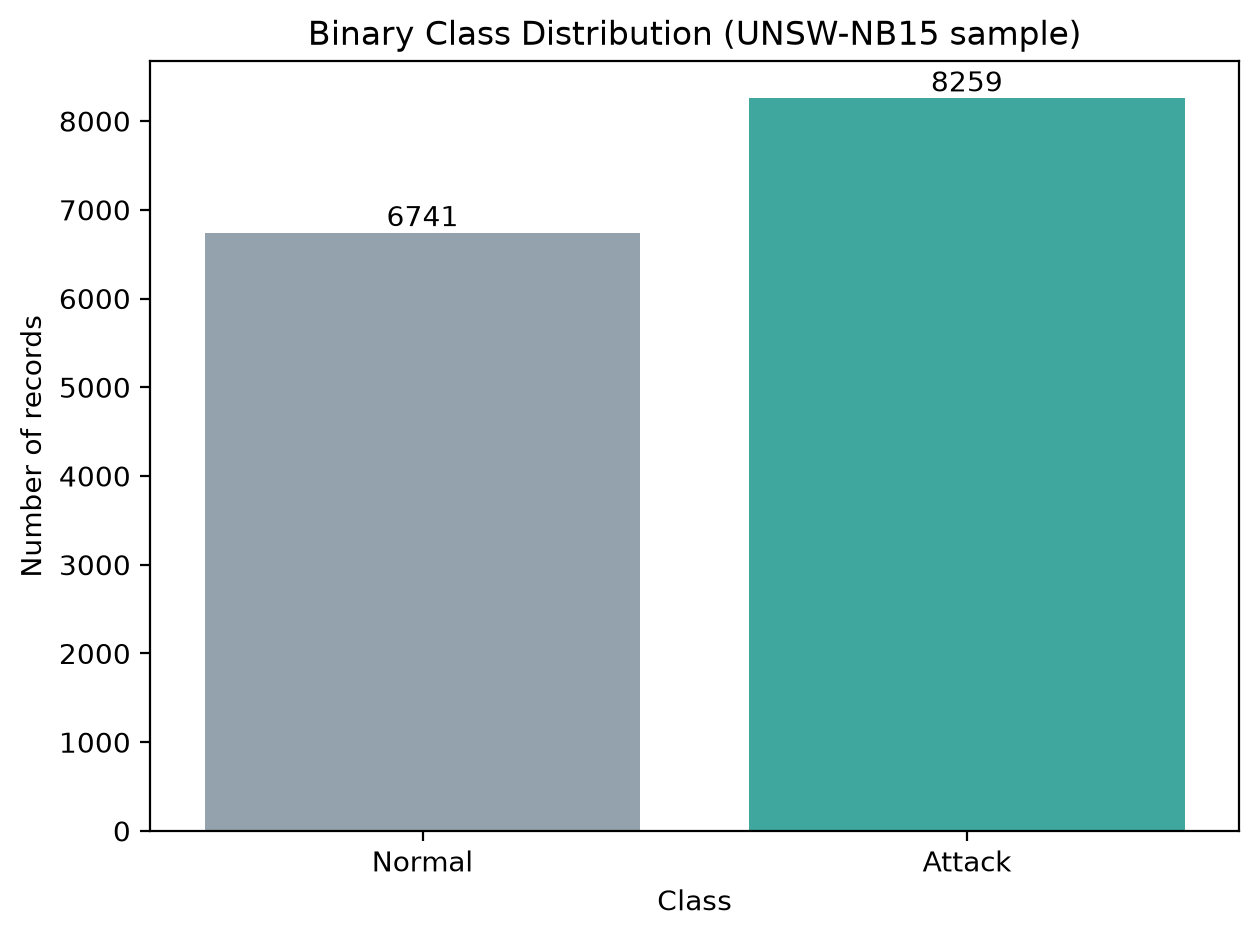

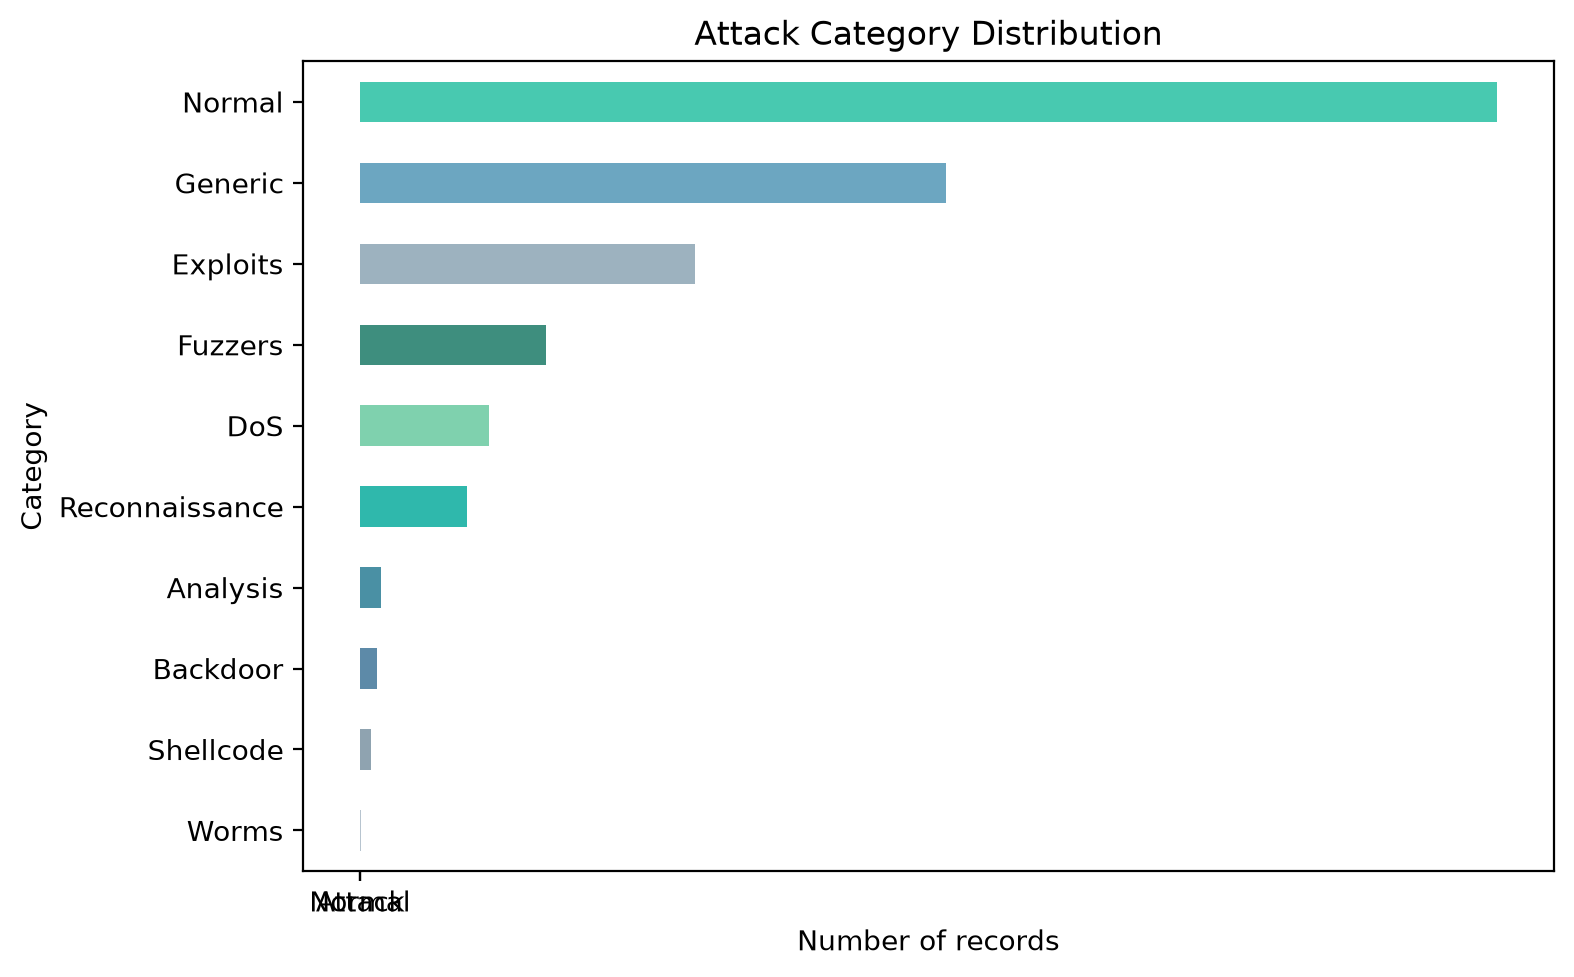

SHA256 dataset.csv: 5a9ca6fa1d14d68d17f35fc4a942c68d061f90bb26bf43c1f308ff9bdc9698f6


In [1]:

import hashlib
from pathlib import Path

import matplotlib
matplotlib.use('Agg')

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

DATA_PATH = Path('../data/dataset.csv')

df = pd.read_csv(DATA_PATH)

print('Rows:', len(df))
print('Columns:', df.shape[1])
print('Missing values total:', int(df.isna().sum().sum()))
print()
print('Class counts:')
print(df['label'].value_counts())
print()
print('Class percentages:')
print((df['label'].value_counts(normalize=True) * 100).round(2))

counts = df['label'].value_counts()
imbalance_ratio = counts.max() / counts.min()
print(f'Imbalance ratio: {imbalance_ratio:.3f}')

df['label_name'] = df['label'].map({0: 'Normal', 1: 'Attack'})

binary_palette = ['#8FA3B0', '#2FB8AC']

ax = sns.countplot(
    x='label_name',
    data=df,
    order=['Normal', 'Attack'],
    palette=binary_palette
)

ax.set_title('Binary Class Distribution (UNSW-NB15 sample)')
ax.set_xlabel('Class')
ax.set_ylabel('Number of records')

for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        str(int(height)),
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=200, bbox_inches='tight')
display(Image(filename='class_distribution.png'))

attack_counts = df['attack_cat'].value_counts().sort_values()

colors = [
    '#B7C4CF',
    '#8FA3B0',
    '#5D8AA8',
    '#4A90A4',
    '#2FB8AC',
    '#7FD1AE',
    '#3E8E7E',
    '#9DB2BF',
    '#6CA6C1',
    '#48C9B0',
]

ax2 = attack_counts.plot(
    kind='barh',
    figsize=(8, 5),
    color=colors[:len(attack_counts)]
)

ax2.set_title('Attack Category Distribution')
ax2.set_xlabel('Number of records')
ax2.set_ylabel('Category')

plt.tight_layout()
plt.savefig('attack_categories.png', dpi=200, bbox_inches='tight')
display(Image(filename='attack_categories.png'))

file_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print(f'SHA256 dataset.csv: {file_hash}')
